In [1]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'House Price Prediction Dataset.csv', 'Untitled.ipynb']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("House Price Prediction Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (2000, 10)

First 5 rows:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056



Column names:
['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage', 'Price']


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDescriptive Statistics:")
display(df.describe())

print("\nCategorical Column Summary:")
display(df[["Location", "Condition", "Garage"]].describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 156.4 KB

Missing Values:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

Duplicate Rows:
0

Descriptive Statistics:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000



Categorical Column Summary:


,Location,Condition,Garage
count,2000,2000,2000
unique,4,4,2
top,Downtown,Fair,No
freq,558,521,1038


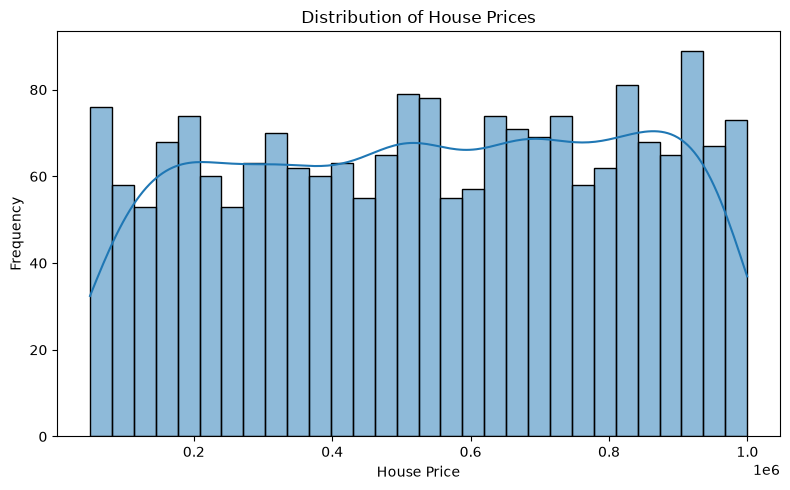

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Price"], bins=30, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Feature Selection Discussion

The target variable for this project is `Price`, which represents the house price to be predicted. The `Area` feature is expected to be an important predictor because larger houses may have higher prices. `Bedrooms`, `Bathrooms`, and `Floors` describe the size and capacity of the house and may influence its value. `YearBuilt` can help represent the age of the property. `Location` may affect price because houses in different areas can have different market values. `Condition` represents the property's state, while `Garage` indicates whether a garage is available.

The `Id` column is only an identifier and is not expected to provide meaningful predictive information, so it will be excluded from model training. Categorical features such as `Location`, `Condition`, and `Garage` will be converted into numerical features using One-Hot Encoding before training the model.

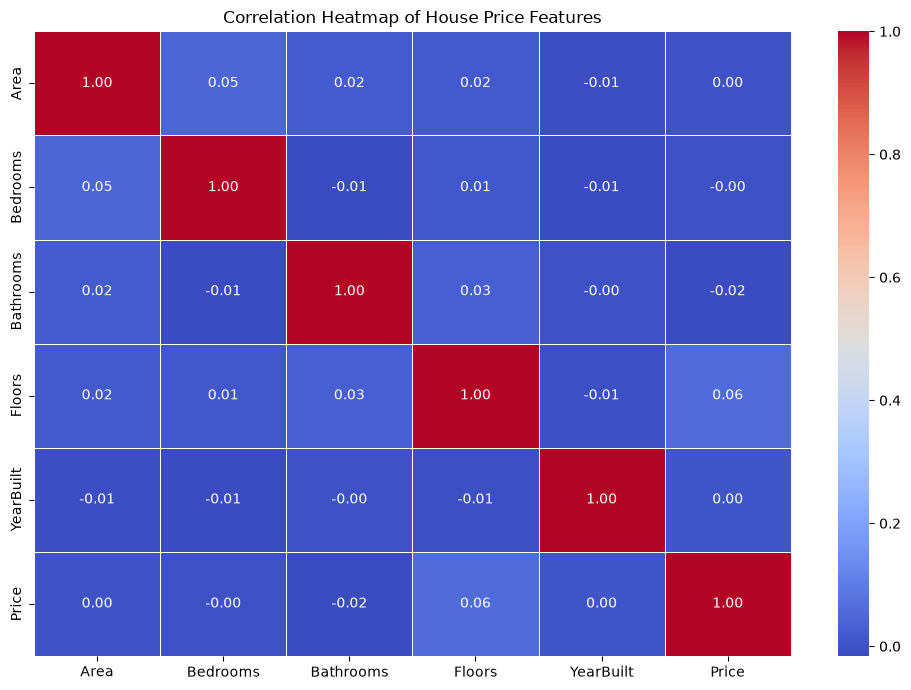

In [5]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.drop(columns=["Id"]).corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of House Price Features")
plt.tight_layout()
plt.show()

### Correlation Heatmap

Correlation analysis is used to identify the relationship between numerical features and house prices. A correlation coefficient ranges from -1 to +1. A positive value indicates that two variables tend to increase together, while a negative value indicates an inverse relationship. A value close to zero indicates a weak linear relationship.

The heatmap visualizes the correlation between numerical features such as Area, Bedrooms, Bathrooms, Floors, YearBuilt, and Price. This analysis helps identify numerical features that may be useful for predicting house prices. However, correlation does not necessarily imply causation.

In [6]:
price_corr = correlation["Price"].drop("Price")
price_corr = price_corr.sort_values(ascending=False)

print("Correlation of each numerical feature with Price:")
display(price_corr.to_frame(name="Correlation with Price"))

Correlation of each numerical feature with Price:


,Correlation with Price
Floors,0.055890
YearBuilt,0.004845
Area,0.001542
Bedrooms,-0.003471
Bathrooms,-0.015737


### Correlation Analysis

The correlation values between the numerical features and the target variable, Price, are examined to understand which features have stronger linear relationships with house prices. The results will be used to support feature selection and model interpretation.

### Data Preprocessing

Data preprocessing prepares the dataset for machine learning. The target variable is Price, and the Id column is excluded because it is only a record identifier. Missing values will be handled using the median for numerical features and the most frequent value for categorical features. One-Hot Encoding will convert categorical features such as Location, Condition, and Garage into numerical representations. The dataset will then be divided into 80% training data and 20% testing data.

A preprocessing pipeline is used to ensure that missing-value imputation and encoding are fitted only on the training data, helping prevent data leakage.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [10]:
X = df.drop(columns=["Id", "Price"])
y = df["Price"]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target variable:", y.name)

Numerical features: ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt']
Categorical features: ['Location', 'Condition', 'Garage']
Target variable: Price


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 1600
Testing rows: 400


### Handling Missing Values and One-Hot Encoding

Numerical features are processed using median imputation, while categorical features are processed using the most frequent value. One-Hot Encoding converts categorical values into numerical columns that can be used by the Linear Regression algorithm. A ColumnTransformer combines both preprocessing steps into one pipeline. The pipeline is fitted using training data only to avoid data leakage.

In [11]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [12]:
from sklearn.linear_model import LinearRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Linear Regression model trained successfully!")
print("Number of predictions:", len(y_pred))

Linear Regression model trained successfully!
Number of predictions: 400


### Model Evaluation

The trained Linear Regression model is evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R² score. MSE measures the average squared difference between actual and predicted prices. RMSE is the square root of MSE and expresses prediction error in the same unit as the target variable. The R² score indicates how much of the variation in house prices is explained by the model. Lower MSE and RMSE values are desirable, while an R² score closer to 1 generally indicates a better fit.

In [13]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
Mean Squared Error (MSE): 78321466146.03
Root Mean Squared Error (RMSE): 279859.73
R2 Score: -0.0067


### Actual vs Predicted House Prices

The actual versus predicted scatter plot is used to visually evaluate the Linear Regression model. Actual prices are plotted on the x-axis, and predicted prices are plotted on the y-axis. The diagonal reference line represents perfect predictions. Points closer to this line indicate more accurate predictions, while points farther away indicate larger prediction errors.

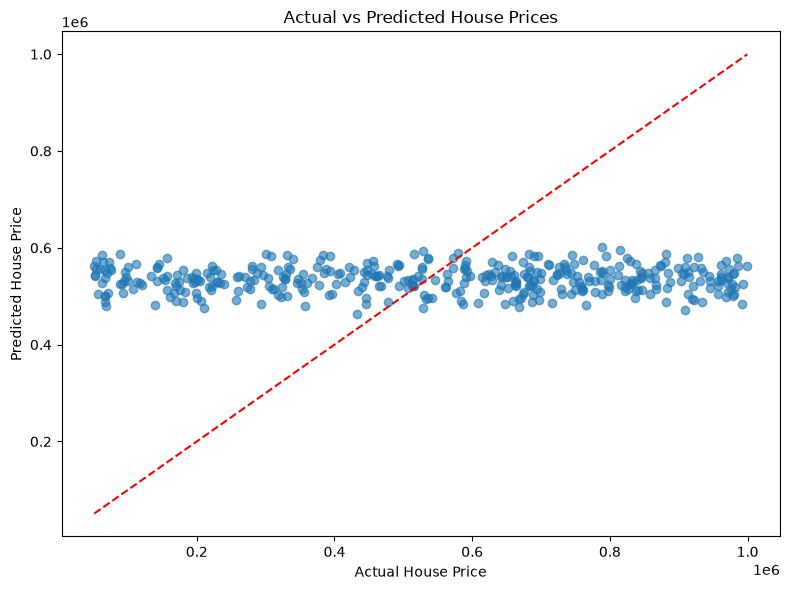

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

### Residual Analysis

Residual analysis helps identify patterns in the prediction errors. Residuals are calculated by subtracting predicted prices from actual prices. Ideally, residuals should be randomly scattered around the zero line without a clear systematic pattern. A visible pattern or very large residuals may indicate that the model does not adequately capture the relationship between the features and house prices.

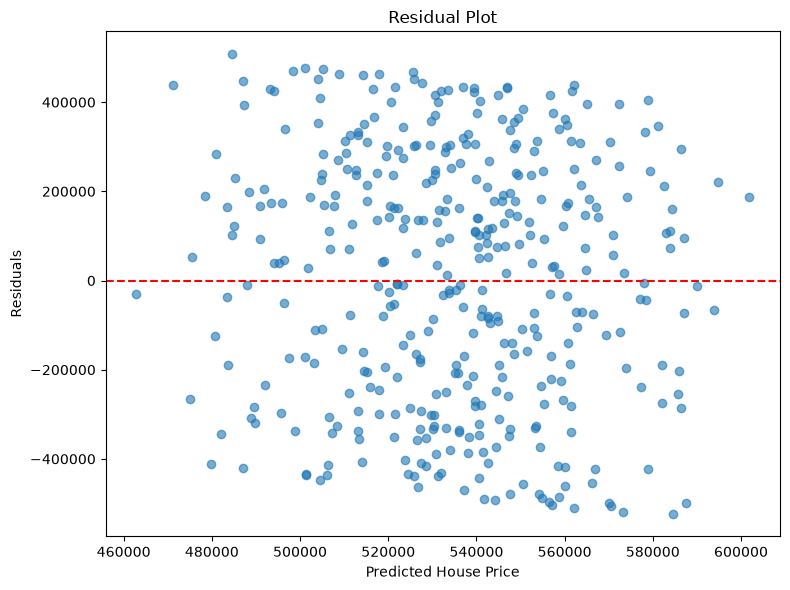

In [15]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

### Feature Coefficient Analysis

Feature coefficient analysis helps understand how each feature influences the predictions made by the Linear Regression model. Positive coefficients increase the predicted price when the corresponding feature increases or is present, while negative coefficients decrease the predicted price, with other features held constant. For categorical features, coefficients represent the encoded categories relative to a reference category. Coefficients should be interpreted carefully because their magnitudes depend on the feature scales and encoding.

In [16]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["regressor"].coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Impact"] = np.where(
    coef_df["Coefficient"] > 0,
    "Positive",
    "Negative"
)

print("Highest Positive Coefficients")
display(coef_df.sort_values("Coefficient", ascending=False).head(10))

print("Most Negative Coefficients")
display(coef_df.sort_values("Coefficient", ascending=True).head(10))

Highest Positive Coefficients


,Feature,Coefficient,Impact
3,num__Floors,23727.983633,Positive
10,cat__Condition_Fair,20279.424861,Positive
7,cat__Location_Suburban,11484.336584,Positive
6,cat__Location_Rural,1289.888789,Positive
14,cat__Garage_Yes,1186.765289,Positive
12,cat__Condition_Poor,269.385945,Positive
4,num__YearBuilt,117.613885,Positive
1,num__Bedrooms,76.784827,Positive
0,num__Area,-0.575754,Negative
5,cat__Location_Downtown,-27.653231,Negative


Most Negative Coefficients


,Feature,Coefficient,Impact
11,cat__Condition_Good,-16744.927821,Negative
8,cat__Location_Urban,-12746.572142,Negative
2,num__Bathrooms,-9662.248234,Negative
9,cat__Condition_Excellent,-3803.882985,Negative
13,cat__Garage_No,-1186.765289,Negative
5,cat__Location_Downtown,-27.653231,Negative
0,num__Area,-0.575754,Negative
1,num__Bedrooms,76.784827,Positive
4,num__YearBuilt,117.613885,Positive
12,cat__Condition_Poor,269.385945,Positive


### Ridge Regression Comparison

Ridge Regression is a regularized version of Linear Regression that adds a penalty to large model coefficients. It can help reduce overfitting and improve generalization in some datasets. In this experiment, Ridge Regression is trained using the same preprocessing steps and training data as the Linear Regression model. Both models are compared using MSE, RMSE, and R² score to identify which performs better on the test dataset.

In [17]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "MSE": [mse, ridge_mse],
    "RMSE": [rmse, ridge_rmse],
    "R2 Score": [r2, ridge_r2]
})

display(comparison.round(4))

,Model,MSE,RMSE,R2 Score
0,Linear Regression,7.832147e+10,279859.7258,-0.0067
1,Ridge Regression,7.832107e+10,279859.0116,-0.0067


## Conclusion

In this project, a house price prediction model was developed using Linear Regression. The dataset contained 2,000 records and 10 columns, including numerical and categorical house features. Initial data analysis confirmed that there were no missing values or duplicate records. The Id column was excluded from model training because it serves only as an identifier. Categorical features such as Location, Condition, and Garage were converted into numerical representations using One-Hot Encoding.

The dataset was divided into 80% training data and 20% testing data. A preprocessing pipeline was created to handle missing values and encode categorical features. The Linear Regression model was trained and evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² score. The model obtained an RMSE of approximately 279,859.73 and an R² score of -0.0067.

Ridge Regression was also tested for comparison. It produced a very small reduction in RMSE, but the R² score remained approximately -0.0067. These results indicate that neither model explains the variation in house prices effectively on the test dataset. Further improvements may include examining feature relationships, selecting more informative features, tuning model parameters, and testing other regression algorithms. This project demonstrates the complete workflow of data preprocessing, model training, evaluation, and comparison for a house price prediction task.